Missing B0 map: data/all_b0_maps/b0_map_position1_IFFT_OrderNA.npy


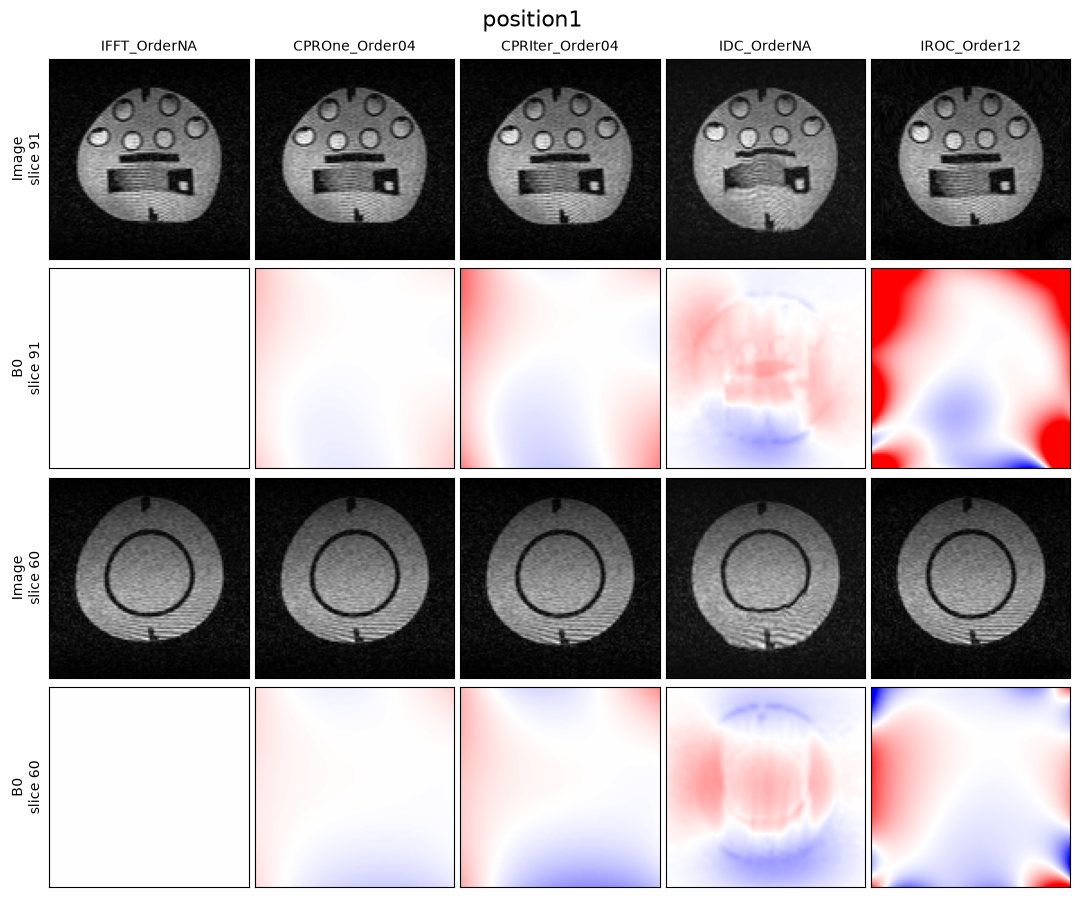

Missing B0 map: data/all_b0_maps/b0_map_position2_IFFT_OrderNA.npy


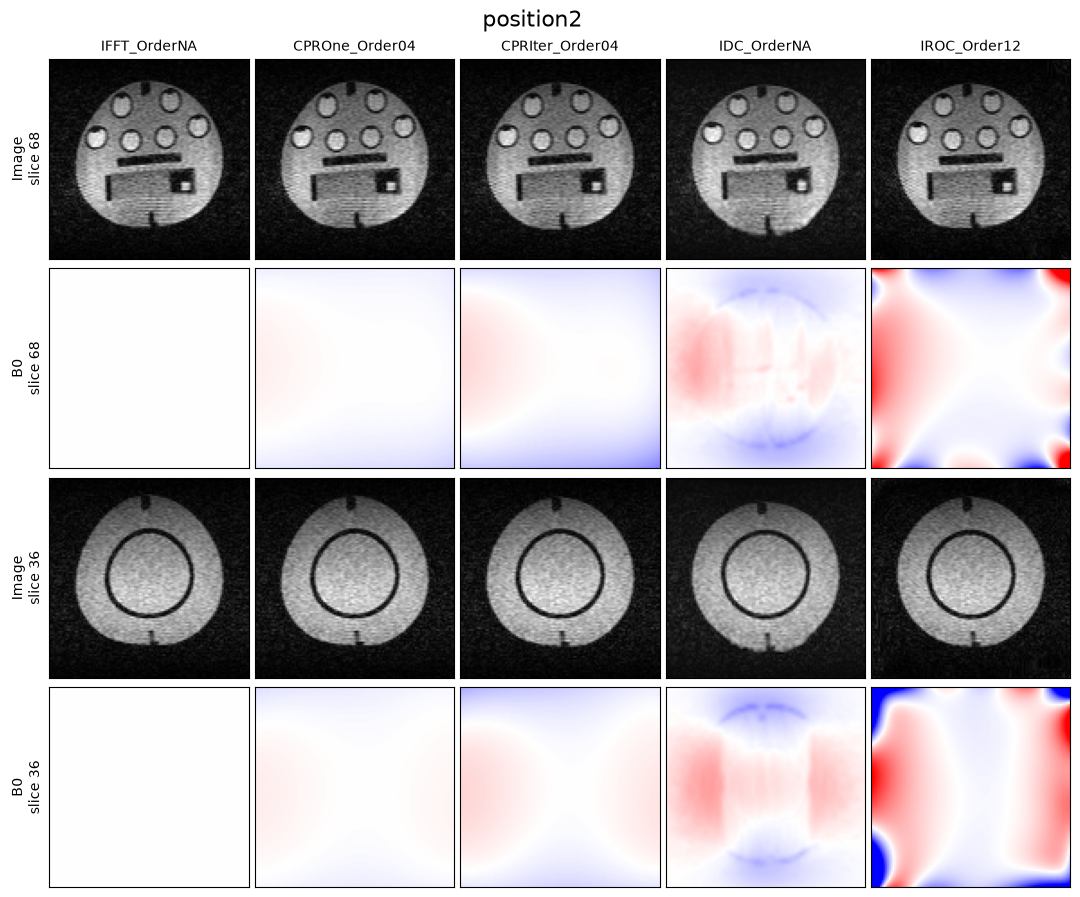

Missing B0 map: data/all_b0_maps/b0_map_position3_IFFT_OrderNA.npy


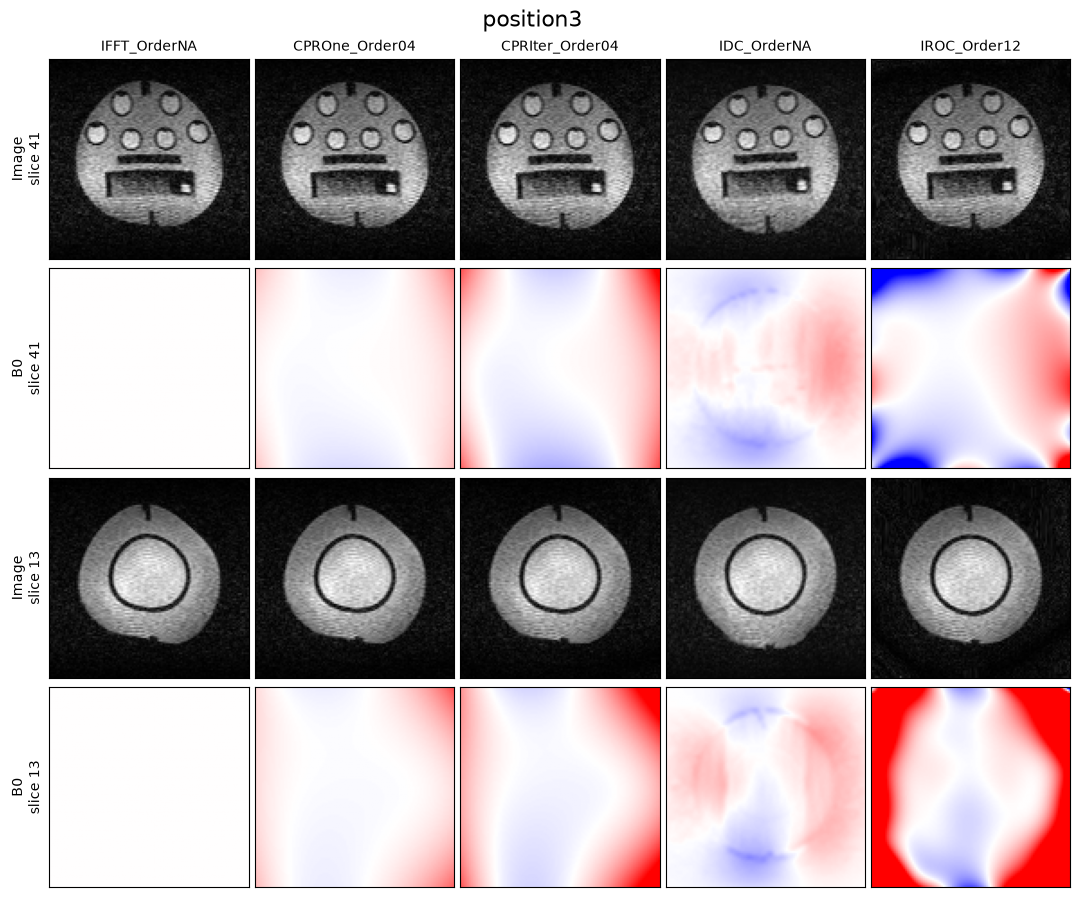

In [12]:
import src.read_write as rw
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ---- Directories ----
dir_reconstruction = Path("data/all_reconstructions")
dir_b0_maps = Path("data/all_b0_maps")

positions = ["position1", "position2", "position3"]

techniques = [
    "IFFT_OrderNA",
    "CPROne_Order04",
    "CPRIter_Order04",
    "IDC_OrderNA",
    "IROC_Order12",
]

# ---- Slice positions ----
slice_indices = {
    "position1": {"top": 91, "bottom": 60},
    "position2": {"top": 68, "bottom": 36},
    "position3": {"top": 41, "bottom": 13},
}

zero_array = np.zeros((111, 111, 111))

# ---- Fixed B0 color scale ----
B0_VMIN = -3000
B0_VMAX = 3000


for position in positions:

    slice_top = slice_indices[position]["top"]
    slice_bottom = slice_indices[position]["bottom"]

    # ==================================================
    # Figure
    # ==================================================

    fig, axes = plt.subplots(
        4,
        5,
        figsize=(11, 9),
        gridspec_kw={
            "wspace": 0.02,
            "hspace": 0.05,
        }
    )

    for col, technique in enumerate(techniques):

        # ==================================================
        # Load reconstruction
        # ==================================================

        nii_file = (
            dir_reconstruction
            / f"{position}_ROreg_ES000_{technique}.nii.gz"
        )

        if nii_file.exists():
            _, img = rw.load_nii(nii_file)
        else:
            print(f"Missing reconstruction: {nii_file}")
            img = zero_array.copy()

        # ==================================================
        # Load B0
        # ==================================================

        b0_file = (
            dir_b0_maps
            / f"b0_map_{position}_{technique}.npy"
        )

        if b0_file.exists():
            b0 = np.load(b0_file)
        else:
            print(f"Missing B0 map: {b0_file}")
            b0 = zero_array.copy()

        # ==================================================
        # Top slice
        # ==================================================

        axes[0, col].imshow(
            img[:, :, slice_top],
            cmap="gray"
        )

        axes[1, col].imshow(
            b0[:, :, slice_top],
            cmap="bwr",
            vmin=B0_VMIN,
            vmax=B0_VMAX
        )

        # ==================================================
        # Bottom slice
        # ==================================================

        axes[2, col].imshow(
            img[:, :, slice_bottom],
            cmap="gray"
        )

        axes[3, col].imshow(
            b0[:, :, slice_bottom],
            cmap="bwr",
            vmin=B0_VMIN,
            vmax=B0_VMAX
        )

        # ---- Column title ----
        axes[0, col].set_title(
            technique,
            fontsize=10
        )

    # ==================================================
    # Row labels
    # ==================================================

    axes[0, 0].set_ylabel(
        f"Image\nslice {slice_top}",
        fontsize=10
    )

    axes[1, 0].set_ylabel(
        f"B0\nslice {slice_top}",
        fontsize=10
    )

    axes[2, 0].set_ylabel(
        f"Image\nslice {slice_bottom}",
        fontsize=10
    )

    axes[3, 0].set_ylabel(
        f"B0\nslice {slice_bottom}",
        fontsize=10
    )

    # ==================================================
    # Remove axes
    # ==================================================

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    # ==================================================
    # Title and spacing
    # ==================================================

    fig.suptitle(
        position,
        fontsize=16,
        y=0.995
    )

    plt.subplots_adjust(
        left=0.06,
        right=0.99,
        top=0.94,
        bottom=0.02,
        wspace=0.02,
        hspace=0.05
    )

    plt.show()